In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RAW, OUT, FIG = "../data/raw", "../data/processed", "../figures"
for d in (OUT, FIG):
    os.makedirs(d, exist_ok=True)
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

# ---- project settings ----
RANDOM_STATE = 42
TARGET = "quality_of_sleep"                 # regression target (score)
CLASS = "sleep_quality_class"               # classification target (low / medium / high)
CLASS_ORDER = ["low", "medium", "high"]
NUM_FEATURES = ["age", "daily_steps", "heart_rate", "physical_activity_level",
                "sleep_duration", "stress_level"]
CAT_FEATURES = ["gender", "bmi_category"]
FEATURES = ["age", "gender", "bmi_category", "daily_steps", "heart_rate",
            "physical_activity_level", "sleep_duration", "stress_level"]   # never include TARGET or CLASS here

def build_preprocessor():
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                     sparse_output=False))])
    return ColumnTransformer([("num", numeric, NUM_FEATURES), ("cat", categorical, CAT_FEATURES)])

log = {}      # numbers we need later for the report (saved to JSON at the end)

In [4]:
FILE1 = "Sleep_health_and_lifestyle_dataset.csv"
FILE2 = "sleep-health-lifestyle.csv"
df1 = pd.read_csv(f"{RAW}/{FILE1}", keep_default_na=False, na_values=[""])
df2 = pd.read_csv(f"{RAW}/{FILE2}", keep_default_na=False, na_values=[""])
print("dataset 1:", df1.shape, "| dataset 2:", df2.shape)

print(df1["Sleep Disorder"].value_counts())
log["raw_rows_df1"], log["raw_rows_df2"] = len(df1), len(df2)

dataset 1: (374, 13) | dataset 2: (2020, 15)
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


In [ ]:
def clean_cols(df):
    df = df.copy()
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace(r"[^\w]+", "_", regex=True).str.strip("_"))
    return df

df1, df2 = clean_cols(df1), clean_cols(df2)
print("Only in df1:", sorted(set(df1.columns) - set(df2.columns)))
print("Only in df2:", sorted(set(df2.columns) - set(df1.columns)))
print("In both:", sorted(set(df1.columns) & set(df2.columns)))

In [4]:
# Same variable, different name in dataset 2 -> rename to dataset 1's name
rename_map = {
    "heart_rate_bpm": "heart_rate",
    "quality_of_sleep_1_10": "quality_of_sleep",
    "sleep_duration_hours": "sleep_duration",
    "stress_level_1_10": "stress_level",
    "physical_activity_minutes_per_day": "physical_activity_level",
}
df2 = df2.rename(columns=rename_map)
shared_cols = sorted(set(df1.columns) & set(df2.columns))
print("Shared columns after renaming (%d):" % len(shared_cols), shared_cols)
print("Only in df1 (cannot be merged):", sorted(set(df1.columns) - set(df2.columns)))
print("Only in df2 (cannot be merged):", sorted(set(df2.columns) - set(df1.columns)))
log["shared_columns"] = shared_cols

Shared columns after renaming (9): ['age', 'bmi_category', 'daily_steps', 'gender', 'heart_rate', 'physical_activity_level', 'quality_of_sleep', 'sleep_duration', 'stress_level']
Only in df1 (cannot be merged): ['blood_pressure', 'occupation', 'person_id', 'sleep_disorder']
Only in df2 (cannot be merged): ['alcohol_drinks_per_week', 'health_risk', 'health_risk_score', 'married', 'smoking', 'sugar_intake_g_per_day']


In [5]:
def lower_text(df):
    df = df.copy()
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].str.strip().str.lower()
    return df

df1, df2 = lower_text(df1), lower_text(df2)

# Dataset 1 uses two labels for the same BMI group
print("BMI categories before:", sorted(df1["bmi_category"].unique()))
df1["bmi_category"] = df1["bmi_category"].replace({"normal weight": "normal"})
print("BMI categories after :", sorted(df1["bmi_category"].unique()))
print("BMI in dataset 2     :", sorted(df2["bmi_category"].unique()))
print("Gender               :", sorted(df1["gender"].unique()), sorted(df2["gender"].unique()))

BMI categories before: ['normal', 'normal weight', 'obese', 'overweight']
BMI categories after : ['normal', 'obese', 'overweight']
BMI in dataset 2     : ['normal', 'overweight', 'underweight']
Gender               : ['female', 'male'] ['female', 'male']


In [ ]:
num_shared = []

for c in shared_cols:
    if pd.api.types.is_numeric_dtype(df1[c]):
        num_shared.append(c)

stats1 = df1[num_shared].agg(["min", "max", "mean"])

stats2 = df2[num_shared].agg(["min", "max", "mean"])

ranges = pd.concat(
    {"dataset1": stats1, "dataset2": stats2},
    axis=1
)

ranges = ranges.T.round(2)

ranges


min      max     mean
dataset1 age                        27.0     59.0    42.18
         daily_steps              3000.0  10000.0  6816.84
         heart_rate                 65.0     86.0    70.17
         physical_activity_level    30.0     90.0    59.17
         quality_of_sleep            4.0      9.0     7.31
         sleep_duration              5.8      8.5     7.13
         stress_level                3.0      8.0     5.39
dataset2 age                         5.0     80.0    45.69
         daily_steps              1000.0  19186.0  6853.41
         heart_rate                 52.0    200.0    71.96
         physical_activity_level     0.0    162.9    60.92
         quality_of_sleep            2.2     10.0     7.03
         sleep_duration              4.0     15.0     6.90
         stress_level                1.0     10.0     4.91

In [ ]:
#Duplicates inside each file (dataset 1: ignore Person ID, it only makes copies look different)
df1_u = df1.drop(columns="person_id").drop_duplicates()
df2_u = df2.drop_duplicates()
log["dup_removed_df1"] = len(df1) - len(df1_u)
log["dup_removed_df2"] = len(df2) - len(df2_u)
print(f"Dataset 1: {len(df1)} -> {len(df1_u)} rows ({log['dup_removed_df1']} exact duplicates removed)")
print(f"Dataset 2: {len(df2)} -> {len(df2_u)} rows ({log['dup_removed_df2']} exact duplicates removed)")

# Merge on the shared columns only (no values are invented for columns that exist in one file)
merged = pd.concat([df1_u[shared_cols].assign(source="dataset1"),
                    df2_u[shared_cols].assign(source="dataset2")], ignore_index=True)
log["rows_after_merge"] = len(merged)

#After dropping the extra columns some dataset-1 rows can become identical in the shared columns
n_dup = int(merged.duplicated(subset=shared_cols).sum())
merged = merged.drop_duplicates(subset=shared_cols).reset_index(drop=True)
log["dup_removed_after_merge"] = n_dup
log["rows_after_dedup"] = len(merged)
print(f"Merged rows: {log['rows_after_merge']} | duplicates in shared columns removed: {n_dup} | now: {len(merged)}")
merged["source"].value_counts()

Dataset 1: 374 -> 132 rows (242 exact duplicates removed)
Dataset 2: 2020 -> 2000 rows (20 exact duplicates removed)
Merged rows: 2132 | duplicates in shared columns removed: 26 | now: 2106


source
dataset2    2000
dataset1     106
Name: count, dtype: int64

In [8]:
# 5a. Missing values in the merged data
miss = merged.isna().sum()
miss = miss[miss > 0]
print(pd.DataFrame({"missing": miss, "percent": (miss / len(merged) * 100).round(2)}))
print("\nWhich file are they from?")
print(merged[merged.isna().any(axis=1)]["source"].value_counts())
assert merged[TARGET].notna().all(), "target must never be missing"
log["missing_before_imputation"] = {k: int(v) for k, v in miss.items()}

# 5b. "None" in sleep disorder: kept as a real category (it only exists in dataset 1)
print("\nSleep disorder in dataset 1 after de-duplication (missing =", int(df1_u["sleep_disorder"].isna().sum()), "):")
print(df1_u["sleep_disorder"].value_counts())

              missing  percent
stress_level       63     2.99

Which file are they from?
source
dataset2    63
Name: count, dtype: int64

Sleep disorder in dataset 1 after de-duplication (missing = 0 ):
sleep_disorder
none           73
sleep apnea    30
insomnia       29
Name: count, dtype: int64


In [9]:
checks = {"age < 18": merged["age"] < 18,
          "heart_rate > 120 bpm": merged["heart_rate"] > 120,
          "sleep_duration > 12 h": merged["sleep_duration"] > 12}
for name, mask in checks.items():
    print(f"{name}: {int(mask.sum())} rows")
invalid = np.logical_or.reduce(list(checks.values()))
print("\nRows removed:", int(invalid.sum()))
print(merged[invalid].head(8).to_string())
log["invalid_rows_removed"] = {k: int(v.sum()) for k, v in checks.items()}
log["invalid_rows_removed_total"] = int(invalid.sum())
merged = merged[~invalid].reset_index(drop=True)
log["rows_final"] = len(merged)
print("\nFinal merged rows:", len(merged), merged["source"].value_counts().to_dict())

age < 18: 5 rows
heart_rate > 120 bpm: 5 rows
sleep_duration > 12 h: 5 rows

Rows removed: 15
      age bmi_category  daily_steps  gender  heart_rate  physical_activity_level  quality_of_sleep  sleep_duration  stress_level    source
140   5.0       normal       4858.0    male        83.0                     42.3               5.5             7.6           6.4  dataset2
174  50.0       normal       1458.0    male       200.0                     21.6               6.7             5.1           4.9  dataset2
309  61.0   overweight       3732.0  female        71.0                     56.5               7.0            15.0           5.1  dataset2
535  19.0       normal       1000.0    male       200.0                      0.0               5.7             4.8           7.0  dataset2
610  35.0       normal      12365.0    male       200.0                    110.1               6.6             6.7           4.2  dataset2
878   5.0       normal       3092.0  female        66.0                 

In [10]:
ext = df1_u.copy()
bp = ext["blood_pressure"].str.extract(r"^\s*(\d+)\s*/\s*(\d+)\s*$")
ext["systolic_bp"] = pd.to_numeric(bp[0])
ext["diastolic_bp"] = pd.to_numeric(bp[1])
assert ext[["systolic_bp", "diastolic_bp"]].notna().all().all(), "some blood pressure values did not parse"
ext = ext.drop(columns="blood_pressure").reset_index(drop=True)
ext["sleep_disorder"] = ext["sleep_disorder"].fillna("none")      # "none" is a category, never missing
print(ext[["systolic_bp", "diastolic_bp"]].describe().round(1))
print(ext["sleep_disorder"].value_counts())

       systolic_bp  diastolic_bp
count        132.0         132.0
mean         128.4          84.5
std            7.8           6.0
min          115.0          75.0
25%          120.8          80.0
50%          130.0          85.0
75%          135.0          88.5
max          142.0          95.0
sleep_disorder
none           73
sleep apnea    30
insomnia       29
Name: count, dtype: int64


In [11]:
print(merged[TARGET].describe().round(2))
BINS = [-np.inf, 6, 8, np.inf]              # low: < 6 | medium: 6 <= s < 8 | high: >= 8

def make_class(score):
    return pd.cut(score, bins=BINS, labels=CLASS_ORDER, right=False).astype(str)

merged[CLASS] = make_class(merged[TARGET])
ext[CLASS] = make_class(ext[TARGET])
dist = merged[CLASS].value_counts().reindex(CLASS_ORDER)
print("\nClass counts :", dist.to_dict())
print("Class share  :", (dist / dist.sum()).round(3).to_dict())
log["class_counts"] = {k: int(v) for k, v in dist.items()}
log["class_share"] = {k: round(float(v), 3) for k, v in (dist / dist.sum()).items()}

count    2091.00
mean        7.04
std         1.39
min         2.20
25%         6.00
50%         7.10
75%         8.00
max        10.00
Name: quality_of_sleep, dtype: float64

Class counts : {'low': 451, 'medium': 1078, 'high': 562}
Class share  : {'low': 0.216, 'medium': 0.516, 'high': 0.269}


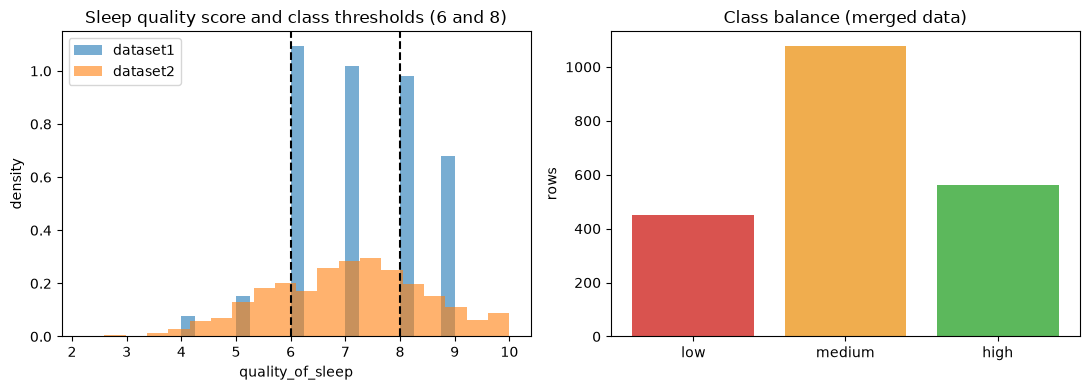

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for s, g in merged.groupby("source"):
    ax[0].hist(g[TARGET], bins=20, alpha=0.6, density=True, label=s)
for t in (6, 8):
    ax[0].axvline(t, color="black", ls="--")
ax[0].set(title="Sleep quality score and class thresholds (6 and 8)", xlabel="quality_of_sleep", ylabel="density")
ax[0].legend()
ax[1].bar(dist.index, dist.values, color=["#d9534f", "#f0ad4e", "#5cb85c"])
ax[1].set(title="Class balance (merged data)", ylabel="rows")
plt.tight_layout()
plt.savefig(f"{FIG}/label_distribution.png", dpi=150)
plt.show()

In [13]:
data = merged[FEATURES + [TARGET, CLASS, "source"]]
train_df, test_df = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE,
                                     stratify=data[CLASS])
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print("train:", train_df.shape, "| test:", test_df.shape)
print("\nClass share  train:", train_df[CLASS].value_counts(normalize=True).reindex(CLASS_ORDER).round(3).to_dict())
print("Class share  test :", test_df[CLASS].value_counts(normalize=True).reindex(CLASS_ORDER).round(3).to_dict())
print("Source share train:", train_df["source"].value_counts(normalize=True).round(3).to_dict())
print("Source share test :", test_df["source"].value_counts(normalize=True).round(3).to_dict())
log["n_train"], log["n_test"] = len(train_df), len(test_df)

X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_reg_train, y_reg_test = train_df[TARGET], test_df[TARGET]
y_clf_train, y_clf_test = train_df[CLASS], test_df[CLASS]

train: (1672, 11) | test: (419, 11)

Class share  train: {'low': 0.216, 'medium': 0.516, 'high': 0.269}
Class share  test : {'low': 0.215, 'medium': 0.516, 'high': 0.27}
Source share train: {'dataset2': 0.95, 'dataset1': 0.05}
Source share test : {'dataset2': 0.945, 'dataset1': 0.055}


In [14]:
preprocessor = build_preprocessor()
Xp_train = preprocessor.fit_transform(X_train)      # learns medians / means / categories from TRAIN only
Xp_test = preprocessor.transform(X_test)            # the same learned values are applied to TEST
names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]
Xp_train = pd.DataFrame(Xp_train, columns=names)
Xp_test = pd.DataFrame(Xp_test, columns=names)

assert not Xp_train.isna().any().any() and not Xp_test.isna().any().any()
medians = {k: round(float(v), 2) for k, v in zip(NUM_FEATURES, preprocessor.named_transformers_["num"].named_steps["impute"].statistics_)}
print("Processed shapes:", Xp_train.shape, Xp_test.shape)
print("Training-set medians used for imputation:", medians)
print("\nTrain mean/std (should be ~0 / ~1 for numeric columns):")
print(Xp_train[NUM_FEATURES].agg(["mean", "std"]).round(2))
print("\nFeature columns:", names)
log["processed_feature_names"] = names
log["train_medians"] = medians

Processed shapes: (1672, 11) (419, 11)
Training-set medians used for imputation: {'age': 45.0, 'daily_steps': 6826.5, 'heart_rate': 72.0, 'physical_activity_level': 60.95, 'sleep_duration': 6.8, 'stress_level': 4.9}

Train mean/std (should be ~0 / ~1 for numeric columns):
      age  daily_steps  heart_rate  physical_activity_level  sleep_duration  stress_level
mean -0.0          0.0         0.0                      0.0             0.0          -0.0
std   1.0          1.0         1.0                      1.0             1.0           1.0

Feature columns: ['age', 'daily_steps', 'heart_rate', 'physical_activity_level', 'sleep_duration', 'stress_level', 'gender_male', 'bmi_category_normal', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_underweight']


In [15]:
# Readable versions (not encoded/scaled), every column incl. targets and source
train_df.to_csv(f"{OUT}/train.csv", index=False)
test_df.to_csv(f"{OUT}/test.csv", index=False)
# Model-ready versions (imputed + encoded + scaled)
Xp_train.to_csv(f"{OUT}/X_train_processed.csv", index=False)
Xp_test.to_csv(f"{OUT}/X_test_processed.csv", index=False)
y_reg_train.to_csv(f"{OUT}/y_reg_train.csv", index=False)
y_reg_test.to_csv(f"{OUT}/y_reg_test.csv", index=False)
y_clf_train.to_csv(f"{OUT}/y_clf_train.csv", index=False)
y_clf_test.to_csv(f"{OUT}/y_clf_test.csv", index=False)
joblib.dump(preprocessor, f"{OUT}/preprocessor.joblib")
# Whole cleaned merged dataset (before the split) for EDA, and the extended dataset-1 file
merged.to_csv(f"{OUT}/merged_clean_v1.csv", index=False)
ext.to_csv(f"{OUT}/dataset1_extended_clean.csv", index=False)
with open(f"{OUT}/preprocessing_log.json", "w") as f:
    json.dump(log, f, indent=2)
print(sorted(os.listdir(OUT)))

['.gitkeep', 'X_test_processed.csv', 'X_train_processed.csv', 'dataset1_extended_clean.csv', 'merged_clean_v1.csv', 'preprocessing_log.json', 'preprocessor.joblib', 'test.csv', 'train.csv', 'y_clf_test.csv', 'y_clf_train.csv', 'y_reg_test.csv', 'y_reg_train.csv']


In [16]:
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, accuracy_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

RES = "../results"
os.makedirs(RES, exist_ok=True)
# X_train, X_test, y_reg_*, y_clf_* already exist from the split in Part 1
print("train:", X_train.shape, "| test:", X_test.shape)

train: (1672, 8) | test: (419, 8)


In [17]:
def pipe(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

reg_models = {
    "Mean predictor (reference)": pipe(DummyRegressor(strategy="mean")),
    "Linear Regression": pipe(LinearRegression()),
}
rows = []
for name, m in reg_models.items():
    cv = cross_validate(m, X_train, y_reg_train, cv=kf, scoring=scoring)
    rows.append({"model": name, "cv_r2": cv["test_r2"].mean(), "cv_r2_std": cv["test_r2"].std(),
                 "cv_mae": -cv["test_mae"].mean(), "cv_rmse": -cv["test_rmse"].mean()})

# Tune Ridge alpha
grid = GridSearchCV(pipe(Ridge()), {"model__alpha": [0.01, 0.1, 1, 10, 30, 100]},
                    cv=kf, scoring="r2")
grid.fit(X_train, y_reg_train)
best_ridge = grid.best_estimator_
cv = cross_validate(best_ridge, X_train, y_reg_train, cv=kf, scoring=scoring)
rows.append({"model": f"Ridge (alpha={grid.best_params_['model__alpha']})", "cv_r2": cv["test_r2"].mean(),
             "cv_r2_std": cv["test_r2"].std(), "cv_mae": -cv["test_mae"].mean(), "cv_rmse": -cv["test_rmse"].mean()})
print("Best Ridge alpha:", grid.best_params_)
reg_cv = pd.DataFrame(rows).round(3)
reg_cv

Best Ridge alpha: {'model__alpha': 10}


,model,cv_r2,cv_r2_std,cv_mae,cv_rmse
0,Mean predictor (reference),-0.007,0.009,1.128,1.401
1,Linear Regression,0.468,0.012,0.821,1.018
2,Ridge (alpha=10),0.468,0.012,0.821,1.018


In [18]:
# Final fit on the full training set, evaluated ONCE on the held-out test set
def reg_test_scores(name, m):
    m.fit(X_train, y_reg_train)
    p = m.predict(X_test)
    return {"task": "regression", "model": name,
            "test_r2": r2_score(y_reg_test, p), "test_mae": mean_absolute_error(y_reg_test, p),
            "test_rmse": mean_squared_error(y_reg_test, p) ** 0.5}

reg_fitted = {**reg_models, f"Ridge (alpha={grid.best_params_['model__alpha']})": best_ridge}
reg_test = pd.DataFrame([reg_test_scores(n, m) for n, m in reg_fitted.items()]).round(3)
reg_test

,task,model,test_r2,test_mae,test_rmse
0,regression,Mean predictor (reference),-0.000,1.103,1.348
1,regression,Linear Regression,0.545,0.710,0.909
2,regression,Ridge (alpha=10),0.545,0.711,0.910


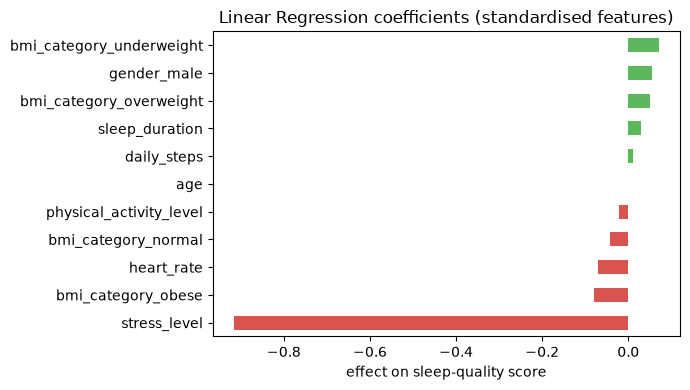

stress_level               -0.916
bmi_category_obese         -0.080
bmi_category_underweight    0.071
heart_rate                 -0.070
gender_male                 0.054
bmi_category_overweight     0.051
bmi_category_normal        -0.042
sleep_duration              0.030
physical_activity_level    -0.022
daily_steps                 0.011
age                        -0.001
dtype: float64

In [19]:
# Which features drive the prediction? (coefficients on standardised features)
lin = reg_fitted["Linear Regression"]
feat_names = [n.split("__", 1)[1] for n in lin.named_steps["prep"].get_feature_names_out()]
coefs = pd.Series(lin.named_steps["model"].coef_, index=feat_names).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
coefs.plot.barh(ax=ax, color=["#d9534f" if v < 0 else "#5cb85c" for v in coefs])
ax.set(title="Linear Regression coefficients (standardised features)", xlabel="effect on sleep-quality score")
plt.tight_layout(); plt.savefig(f"{FIG}/baseline_linear_coefficients.png", dpi=150); plt.show()
coefs.round(3).sort_values(key=abs, ascending=False)

In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring_c = {"accuracy": "accuracy", "f1_macro": "f1_macro"}

clf_models = {"Majority class (reference)": pipe(DummyClassifier(strategy="most_frequent")),
              "Logistic Regression (default)": pipe(LogisticRegression(max_iter=2000))}
rows = []
for name, m in clf_models.items():
    cv = cross_validate(m, X_train, y_clf_train, cv=skf, scoring=scoring_c)
    rows.append({"model": name, "cv_accuracy": cv["test_accuracy"].mean(),
                 "cv_accuracy_std": cv["test_accuracy"].std(), "cv_f1_macro": cv["test_f1_macro"].mean()})

grid_c = GridSearchCV(pipe(LogisticRegression(max_iter=2000)),
                      {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
                      cv=skf, scoring="f1_macro")
grid_c.fit(X_train, y_clf_train)
best_logit = grid_c.best_estimator_
cv = cross_validate(best_logit, X_train, y_clf_train, cv=skf, scoring=scoring_c)
tuned_name = f"Logistic Regression (tuned: C={grid_c.best_params_['model__C']}, class_weight={grid_c.best_params_['model__class_weight']})"
rows.append({"model": tuned_name, "cv_accuracy": cv["test_accuracy"].mean(),
             "cv_accuracy_std": cv["test_accuracy"].std(), "cv_f1_macro": cv["test_f1_macro"].mean()})
print("Best parameters:", grid_c.best_params_)
clf_cv = pd.DataFrame(rows).round(3)
clf_cv

Best parameters: {'model__C': 1, 'model__class_weight': None}


,model,cv_accuracy,cv_accuracy_std,cv_f1_macro
0,Majority class (reference),0.516,0.001,0.227
1,Logistic Regression (default),0.613,0.025,0.570
2,"Logistic Regression (tuned: C=1, class_weight=...",0.613,0.025,0.570


In [21]:
def clf_test_scores(name, m):
    m.fit(X_train, y_clf_train)
    p = m.predict(X_test)
    return {"task": "classification", "model": name, "test_accuracy": accuracy_score(y_clf_test, p),
            "test_f1_macro": f1_score(y_clf_test, p, average="macro")}

clf_fitted = {**clf_models, tuned_name: best_logit}
clf_test = pd.DataFrame([clf_test_scores(n, m) for n, m in clf_fitted.items()]).round(3)
clf_test

,task,model,test_accuracy,test_f1_macro
0,classification,Majority class (reference),0.516,0.227
1,classification,Logistic Regression (default),0.666,0.625
2,classification,"Logistic Regression (tuned: C=1, class_weight=...",0.666,0.625


              precision    recall  f1-score   support

         low      0.673     0.411     0.510        90
      medium      0.649     0.815     0.723       216
        high      0.710     0.584     0.641       113

    accuracy                          0.666       419
   macro avg      0.677     0.603     0.625       419
weighted avg      0.671     0.666     0.655       419



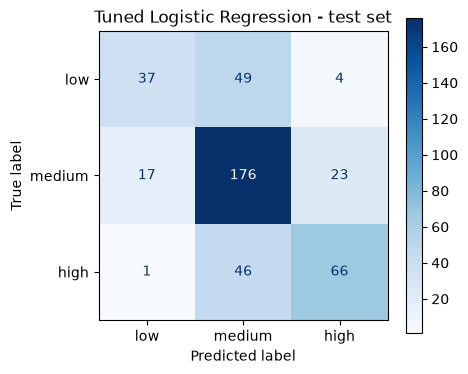

In [22]:
pred = best_logit.predict(X_test)
print(classification_report(y_clf_test, pred, labels=CLASS_ORDER, digits=3))
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_predictions(y_clf_test, pred, labels=CLASS_ORDER, cmap="Blues", ax=ax)
ax.set_title("Tuned Logistic Regression - test set")
plt.tight_layout(); plt.savefig(f"{FIG}/baseline_logistic_confusion_matrix.png", dpi=150); plt.show()

In [23]:
summary = pd.concat([reg_cv.merge(reg_test.drop(columns="task"), on="model"),
                     clf_cv.merge(clf_test.drop(columns="task"), on="model")], ignore_index=True)
summary.to_csv(f"{RES}/baseline_results.csv", index=False)
summary.round(3)

,model,cv_r2,cv_r2_std,cv_mae,cv_rmse,test_r2,test_mae,test_rmse,cv_accuracy,cv_accuracy_std,cv_f1_macro,test_accuracy,test_f1_macro
0,Mean predictor (reference),-0.007,0.009,1.128,1.401,-0.000,1.103,1.348,NaN,NaN,NaN,NaN,NaN
1,Linear Regression,0.468,0.012,0.821,1.018,0.545,0.710,0.909,NaN,NaN,NaN,NaN,NaN
2,Ridge (alpha=10),0.468,0.012,0.821,1.018,0.545,0.711,0.910,NaN,NaN,NaN,NaN,NaN
3,Majority class (reference),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.516,0.001,0.227,0.516,0.227
4,Logistic Regression (default),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.613,0.025,0.570,0.666,0.625
5,"Logistic Regression (tuned: C=1, class_weight=...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.613,0.025,0.570,0.666,0.625
